# Análisis de señales de ciclos de carga y descarga de baterías
## 1. Filtrado de la tensión de una descarga

Vamos a aplicar un filtro paso bajo a la tensión de una descarga completa de la batería B0005, comprobar su efecto y valorar si resulta útil para estimar parámetros sin eliminar cambios reales de la batería.


**1. Librerías**

In [1]:
import json
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from pathlib import Path 
from scipy.signal import butter, sosfiltfilt, sosfreqz 

print("Librerías importadas correctamente")

Librerías importadas correctamente


**2. Parámetros del análisis**

Los únicos valores que se pueden cambiar están en la siguiente celda. El orden y el corte del filtro se justifican más adelante con el muestreo, el espectro y un barrido de cortes.

In [2]:
N_DESCARGA = 1        # descarga a filtrar: 1, 80 o 160 
ORDEN = 4             # orden del filtro Butterworth
FC_FRAC = 0.2         # corte = FC_FRAC * (fs/2)
FC_FRAC_COMP = 0.8    # corte alto, solo para comparar en la Gráfica H2
UMBRAL_I = 0.5        
SOLO_FASE_ACTIVA = True 
V_CRITERIO = 3.2     
ZOOM_CENTRO = (0.40, 0.50)  # tramo central (fracción de la duración)
ZOOM_INICIAL = 0.10         # primera fracción de la descarga
ZOOM_FINAL = 0.10           # última fracción de la descarga

print("Descarga:", N_DESCARGA, "| orden:", ORDEN, "| fc/(fs/2):", FC_FRAC)

Descarga: 1 | orden: 4 | fc/(fs/2): 0.2


## 2. Carga de los datos comunes

Buscamos `mediciones.csv` y `resumen_ciclos.csv` tanto si se ejecuta el Notebook desde la raíz del proyecto como desde la carpeta `notebooks/`. Las figuras se guardan en `graficas/` y las tablas en `resultados/`.

In [3]:
posibles_rutas = [Path("datos_procesados"), Path("../datos_procesados")]
carpeta_csv = next((p for p in posibles_rutas if (p / "mediciones.csv").is_file()), None)

if carpeta_csv is None:
    raise FileNotFoundError(
        "No se encuentra mediciones.csv. Comprueba que está en la carpeta datos_procesados/ "
        "y que has abierto el proyecto correcto en VS Code."
    )

carpeta_proyecto = carpeta_csv.resolve().parent
carpeta_graficas = carpeta_proyecto / "graficas"
carpeta_resultados = carpeta_proyecto / "resultados"
carpeta_graficas.mkdir(exist_ok=True)
carpeta_resultados.mkdir(exist_ok=True)

mediciones = pd.read_csv(carpeta_csv / "mediciones.csv")
resumen_ciclos = pd.read_csv(carpeta_csv / "resumen_ciclos.csv")

print("Columnas de mediciones:", list(mediciones.columns))
print("Columnas de resumen_ciclos:", list(resumen_ciclos.columns))
display(resumen_ciclos.head(3))

Columnas de mediciones: ['bateria', 'registro_original', 'tipo', 'numero_tipo', 'tiempo_s', 'tension_V', 'corriente_A', 'temperatura_C']
Columnas de resumen_ciclos: ['bateria', 'registro_original', 'tipo', 'numero_tipo', 'numero_descarga', 'duracion_s', 'duracion_activa_s', 'capacidad_Ah']


,bateria,registro_original,tipo,numero_tipo,numero_descarga,duracion_s,duracion_activa_s,capacidad_Ah
0,B0005,1,charge,1,NaN,7597.875,1875.015,NaN
1,B0005,2,discharge,1,1.0,3690.234,3311.234,1.856487
2,B0005,3,charge,2,NaN,10516.000,4416.984,NaN


## 3. Selección de la descarga y fase activa

Seleccionamos las filas de la descarga indicada (`tipo == "discharge"` y `numero_tipo == N_DESCARGA`), comprobamos que no hay valores no válidos ni tiempos repetidos y restamos el primer instante para que el tiempo empiece en 0 s.

El registro de una descarga continúa tras cortar la corriente y en ese reposo la tensión se recupera. Esa recuperación no es descarga, así que filtramos solo la fase activa, hasta la última muestra con |corriente| ≥ 0,5 A.

In [4]:
descargas = mediciones[mediciones["tipo"] == "discharge"]
muestras = descargas.groupby("numero_tipo").size()
print("Descargas en mediciones.csv:", len(muestras), "(de", muestras.index.min(), "a", muestras.index.max(), ")")
print("Muestras en las descargas:", {n: int(muestras.get(n, 0)) for n in (1, 80, 160)})

d = descargas[descargas["numero_tipo"] == N_DESCARGA][["tiempo_s", "tension_V", "corriente_A"]].copy()
assert len(d) > 0, f"No existe la descarga {N_DESCARGA}"

n_nan = int(d.isna().any(axis=1).sum())
n_dup = int(d["tiempo_s"].duplicated().sum())
d = d.dropna().sort_values("tiempo_s")
d = d.groupby("tiempo_s", as_index=False).mean()  # si hubiera tiempos repetidos, se promedian

tiempo_reg = d["tiempo_s"].to_numpy() - d["tiempo_s"].iloc[0]
tension_reg = d["tension_V"].to_numpy()
corriente_reg = d["corriente_A"].to_numpy()
assert np.all(np.diff(tiempo_reg) > 0), "El tiempo no es estrictamente creciente"

# Fase activa: de la primera a la última muestra con |corriente| >= UMBRAL_I
activo = np.abs(corriente_reg) >= UMBRAL_I
k_ini = int(np.where(activo)[0].min()) if activo.any() else 0
k_fin = int(np.where(activo)[0].max()) if activo.any() else len(tiempo_reg) - 1

print(f"\nRegistro completo: {len(tiempo_reg)} muestras, {tiempo_reg[-1]:.1f} s")
print(f"Fase activa (|I| >= {UMBRAL_I} A): hasta {tiempo_reg[k_fin]:.1f} s (muestra {k_fin + 1})")
print(f"Tensión mínima = {tension_reg.min():.4f} V · al final de la fase activa = {tension_reg[k_fin]:.4f} V · al final del registro = {tension_reg[-1]:.4f} V")
print(f"Filas con NaN eliminadas: {n_nan} · tiempos duplicados promediados: {n_dup}")

# Comparación con la duración activa 
fila = resumen_ciclos[(resumen_ciclos["tipo"] == "discharge") & (resumen_ciclos["numero_descarga"] == N_DESCARGA)].iloc[0]
print(f"\nduracion_activa_s de Lidia = {fila['duracion_activa_s']:.1f} s · "
      f"primera a última muestra activa aquí = {tiempo_reg[k_fin] - tiempo_reg[k_ini]:.1f} s · "
      f"primera muestra activa en t = {tiempo_reg[k_ini]:.1f} s")

if SOLO_FASE_ACTIVA:
    tiempo, tension = tiempo_reg[:k_fin + 1], tension_reg[:k_fin + 1]
else:
    tiempo, tension = tiempo_reg, tension_reg
print(" Se filtra:", "solo la fase activa" if SOLO_FASE_ACTIVA else "el registro completo (incluye la recuperación)")
print(f"\nSeñal a filtrar: {len(tiempo)} muestras · duración = {tiempo[-1]:.1f} s")
print(f"Tensión: inicial = {tension[0]:.4f} V · final = {tension[-1]:.4f} V · mínima = {tension.min():.4f} V · máxima = {tension.max():.4f} V")

Descargas en mediciones.csv: 168 (de 1 a 168 )
Muestras en las descargas: {1: 197, 80: 330, 160: 299}

Registro completo: 197 muestras, 3690.2 s
Fase activa (|I| >= 0.5 A): hasta 3346.9 s (muestra 180)
Tensión mínima = 2.6125 V · al final de la fase activa = 2.6125 V · al final del registro = 3.2772 V
Filas con NaN eliminadas: 0 · tiempos duplicados promediados: 0

duracion_activa_s de Lidia = 3311.2 s · primera a última muestra activa aquí = 3311.2 s · primera muestra activa en t = 35.7 s
 Se filtra: solo la fase activa

Señal a filtrar: 180 muestras · duración = 3346.9 s
Tensión: inicial = 4.1915 V · final = 2.6125 V · mínima = 2.6125 V · máxima = 4.1915 V


### Interpretación de la selección 

El registro de la descarga 1 tiene 197 muestras y cubre 3690,2 s, pero la corriente deja de ser apreciable hacia los 3346,9 s (muestra 180). En ese instante la tensión es de 2,6125 V, su valor mínimo; después se recupera hasta 3,2772 V sin que haya una nueva carga, por lo que esas 17 muestras se dejan fuera. La señal que se filtra tiene por tanto 180 muestras, con una tensión que baja de 4,1915 V a 2,6125 V.

**Aclaración sobre la duración.** Los 3346,9 s de aquí se miden desde t = 0 hasta la última muestra activa. La columna `duracion_activa_s` del análisis inicial (3311,2 s) se mide desde la primera muestra activa, que no es la primera del registro, por lo que sale unos 36 s menor. El final de la fase activa es el mismo; solo cambia el origen. Hay que tenerlo presente al comparar con la tabla.

## 4. Comprobar el muestreo

Un filtro digital como butter + sosfiltfilt supone muestras separadas. Calculamos las diferencias entre instantes consecutivos (Δt) y comprobamos si la separación es aproximadamente constante. Consideramos el muestreo prácticamente uniforme si al menos el 95 % de los Δt está dentro de ±10 % de la mediana y no hay huecos mayores que el doble de la mediana.

Δt mínimo = 16.781 s · mediana = 18.579 s · media = 18.698 s · máximo = 19.719 s
Dispersión relativa (desv./media): 2.590%
Muestras con Δt dentro de ±10 % de la mediana: 100.0%
Huecos (Δt > 2·mediana): 0

 Muestreo prácticamente uniforme  se remuestrea igualmente a una rejilla exacta


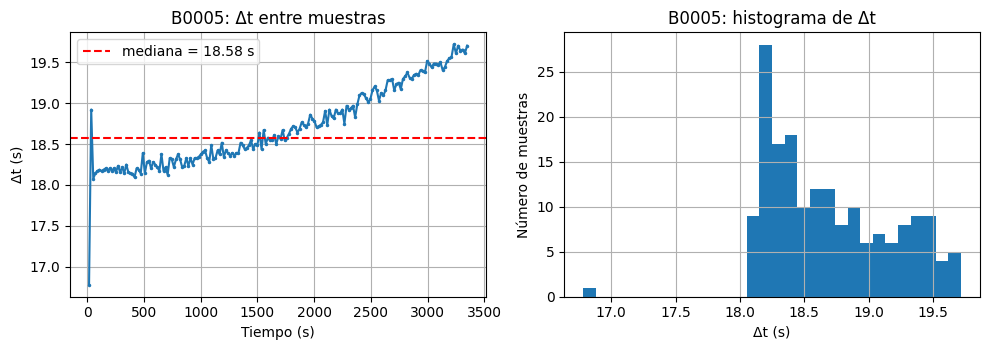

In [5]:
dt = np.diff(tiempo)
dt_med = np.median(dt)
dentro = np.mean(np.abs(dt - dt_med) <= 0.1 * dt_med)
huecos = np.where(dt > 2 * dt_med)[0]

print(f"Δt mínimo = {dt.min():.3f} s · mediana = {dt_med:.3f} s · media = {dt.mean():.3f} s · máximo = {dt.max():.3f} s")
print(f"Dispersión relativa (desv./media): {dt.std() / dt.mean():.3%}")
print(f"Muestras con Δt dentro de ±10 % de la mediana: {dentro:.1%}")
print(f"Huecos (Δt > 2·mediana): {len(huecos)}")

MUESTREO_UNIFORME = bool(dentro >= 0.95 and len(huecos) == 0)
print("\n Muestreo", "prácticamente uniforme" if MUESTREO_UNIFORME else "IRREGULAR",
      " se remuestrea igualmente a una rejilla exacta")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(tiempo[1:], dt, ".-", ms=3)
ax[0].axhline(dt_med, color="r", ls="--", label=f"mediana = {dt_med:.2f} s")
ax[0].set_title("B0005: Δt entre muestras")
ax[0].set_xlabel("Tiempo (s)")
ax[0].set_ylabel("Δt (s)")
ax[0].legend()
ax[0].grid(True)
ax[1].hist(dt, bins=30)
ax[1].set_title("B0005: histograma de Δt")
ax[1].set_xlabel("Δt (s)")
ax[1].set_ylabel("Número de muestras")
ax[1].grid(True)
plt.tight_layout()
plt.show()

**Remuestreo.** Interpolamos linealmente sobre una rejilla uniforme que incluye el primer y el último instante, con un paso próximo a la mediana de Δt. Se usa np.linspace y no np.arange porque excluye el último instante y la señal remuestreada terminaría antes de la última muestra real, la más relevante en una descarga.

In [6]:
n_u = int(round((tiempo[-1] - tiempo[0]) / dt_med)) + 1
tiempo_u = np.linspace(tiempo[0], tiempo[-1], n_u)
dt_u = tiempo_u[1] - tiempo_u[0]
tension_u = np.interp(tiempo_u, tiempo, tension)

fs = 1 / dt_u      
nyq = fs / 2      
print(f"Rejilla uniforme: {n_u} muestras · Δt = {dt_u:.3f} s · fs = {fs:.5f} Hz · Nyquist = fs/2 = {nyq:.5f} Hz")
print(f"Comprobación de extremos: V inicial real/remuestreada = {tension[0]:.4f}/{tension_u[0]:.4f} · V final = {tension[-1]:.4f}/{tension_u[-1]:.4f}")

Rejilla uniforme: 181 muestras · Δt = 18.594 s · fs = 0.05378 Hz · Nyquist = fs/2 = 0.02689 Hz
Comprobación de extremos: V inicial real/remuestreada = 4.1915/4.1915 · V final = 2.6125/2.6125


### Interpretación del muestreo 
El Δt varía entre 16,781 s y 19,719 s con una mediana de 18,579 s; la dispersión relativa es del 2,59 %, el 100 % de las muestras está dentro de ±10 % de la mediana y no hay huecos. El muestreo es prácticamente uniforme, la interpolación lineal apenas modifica la señal: la rejilla resultante tiene 181 muestras con Δt = 18,594 s, **fs = 0,05378 Hz** y una frecuencia de Nyquist de **0,02689 Hz**. Los valores inicial y final coinciden con los reales (4,1915 V y 2,6125 V).

## 5. Señal original y presencia de ruido

Representamos la señal completa y dos ampliaciones (tramo central y final) para ver si existen fluctuaciones rápidas. Para **cuantificar** el ruido usamos la segunda diferencia: si la tensión es una señal lenta más ruido blanco de desviación σ, entonces std(Δ²v) ≈ √6·σ. Es una estimación orientativa que sobreestima σ donde la curva tiene curvatura fuerte, por lo que calculamos también una versión robusta (con la mediana de desviaciones absolutas) y otra solo en el tramo central, donde la curva es casi recta.

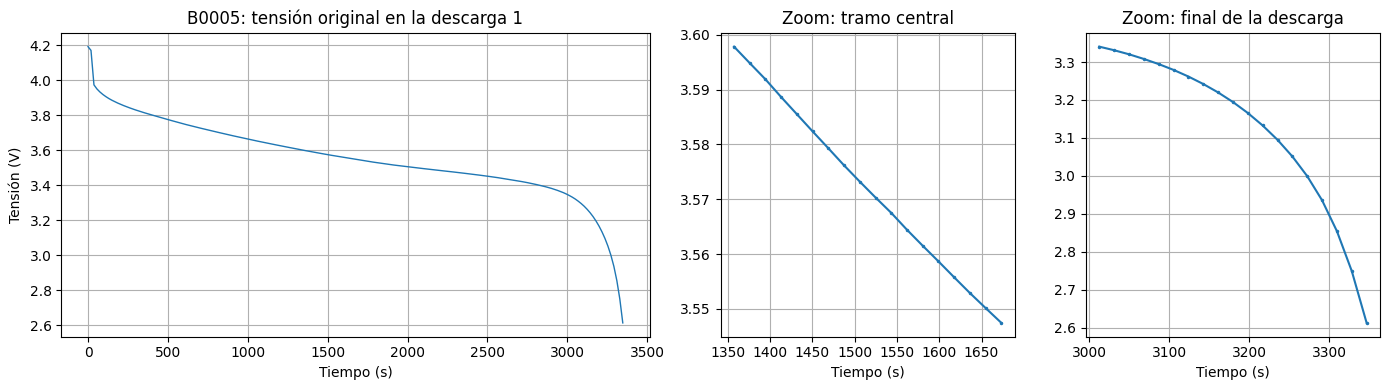

σ de ruido (2.ª diferencia) ≈ 7.68 mV · ΔV total = 1.579 V → σ/ΔV = 0.486%
σ robusta ≈ 0.109 mV · σ solo en el tramo central ≈ 0.052 mV · σ robusta/ΔV = 0.007%
Resolución del dato (salto mínimo no nulo entre muestras originales): 0.743 mV


In [7]:
def sigma_ruido(x):
    return np.std(np.diff(x, 2)) / np.sqrt(6)

def sigma_robusta(x):
    d2 = np.diff(x, 2)
    return 1.4826 * np.median(np.abs(d2 - np.median(d2))) / np.sqrt(6)

dur = tiempo_u[-1] - tiempo_u[0]
m_centro = (tiempo_u >= ZOOM_CENTRO[0] * dur) & (tiempo_u <= ZOOM_CENTRO[1] * dur)
m_final = tiempo_u >= (1 - ZOOM_FINAL) * dur
m_inicio = tiempo_u <= ZOOM_INICIAL * dur

fig, ax = plt.subplots(1, 3, figsize=(14, 4), gridspec_kw={"width_ratios": [2, 1, 1]})
ax[0].plot(tiempo_u, tension_u, lw=1)
ax[0].set_title(f"B0005: tensión original en la descarga {N_DESCARGA}")
ax[1].plot(tiempo_u[m_centro], tension_u[m_centro], ".-", ms=3)
ax[1].set_title("Zoom: tramo central")
ax[2].plot(tiempo_u[m_final], tension_u[m_final], ".-", ms=3)
ax[2].set_title("Zoom: final de la descarga")
for a in ax:
    a.set_xlabel("Tiempo (s)")
    a.grid(True)
ax[0].set_ylabel("Tensión (V)")
plt.tight_layout()
plt.show()

sigma0 = sigma_ruido(tension_u)
sigma_rob0 = sigma_robusta(tension_u)
dV0 = tension_u[0] - tension_u[-1]
saltos = np.abs(np.diff(tension))
print(f"σ de ruido (2.ª diferencia) ≈ {1e3 * sigma0:.2f} mV · ΔV total = {dV0:.3f} V → σ/ΔV = {sigma0 / dV0:.3%}")
print(f"σ robusta ≈ {1e3 * sigma_rob0:.3f} mV · σ solo en el tramo central ≈ {1e3 * sigma_ruido(tension_u[m_centro]):.3f} mV · σ robusta/ΔV = {sigma_rob0 / dV0:.3%}")
print(f"Resolución del dato (salto mínimo no nulo entre muestras originales): {1e3 * saltos[saltos > 0].min():.3f} mV")

### Interpretación de la señal original

La tensión muestra una caída rápida en los primeros instantes, una larga zona casi lineal y una caída final pronunciada. En el tramo central la curva es una recta sin dispersión visible. La σ por segunda diferencia es de 7,68 mV (0,486 % de ΔV = 1,579 V), pero procede sobre todo de la curvatura de la caída inicial y de la rodilla: la σ robusta baja a **0,109 mV** (0,007 % de ΔV), en el tramo central es de 0,052 mV y la resolución del dato es de 0,743 mV. Es decir, **la señal apenas contiene ruido**.

## 6. Elección de la frecuencia de corte

Un Butterworth paso bajo deja pasar las variaciones **lentas** (la tendencia de descarga) y atenúa las **rápidas** (ruido de medida). La frecuencia de corte debe cumplir f<sub>c</sub> < f<sub>s</sub>/2:

- Si es demasiado alta, el ruido pasa y el filtro no sirve de nada.
- Si es demasiado baja, elimina cambios reales (sobre todo la caída final) y distorsiona los extremos.

Para elegirla con datos usamos dos ayudas: (a) el **espectro** de la tensión sin tendencia lineal, para ver dónde está la energía, y (b) un **barrido** de cortes midiendo cuánto se aleja la señal filtrada de la original.

El 99 % de la energía está por debajo de 0.00059 Hz (2.2% de Nyquist)
El 99,9 % está por debajo de 0.00089 Hz (3.3% de Nyquist)


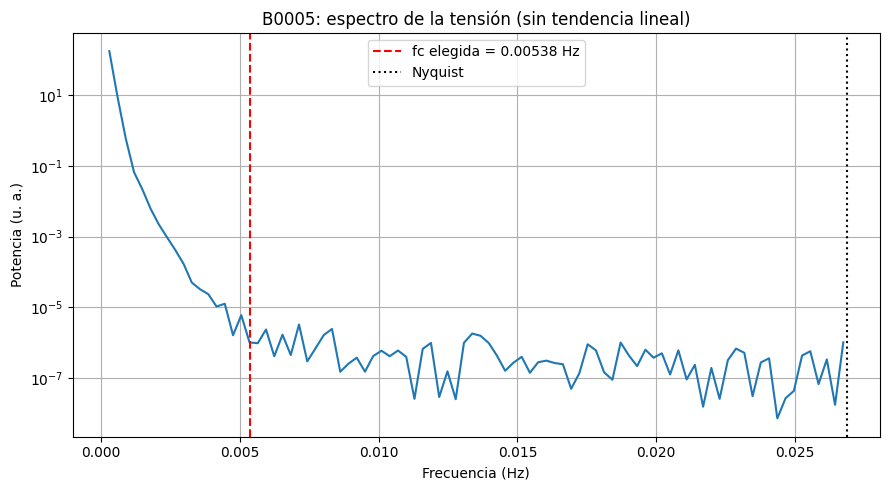

In [8]:
# (a) Espectro: se resta la recta que une los extremos y se aplica una ventana de Hann
recta = np.interp(tiempo_u, [tiempo_u[0], tiempo_u[-1]], [tension_u[0], tension_u[-1]])
x = (tension_u - recta) * np.hanning(len(tension_u))
frec = np.fft.rfftfreq(len(x), d=dt_u)
potencia = np.abs(np.fft.rfft(x)) ** 2
energia = np.cumsum(potencia) / potencia.sum()
f99 = frec[np.searchsorted(energia, 0.99)]
f999 = frec[np.searchsorted(energia, 0.999)]
print(f"El 99 % de la energía está por debajo de {f99:.5f} Hz ({f99 / nyq:.1%} de Nyquist)")
print(f"El 99,9 % está por debajo de {f999:.5f} Hz ({f999 / nyq:.1%} de Nyquist)")

plt.figure(figsize=(9, 5))
plt.semilogy(frec[1:], potencia[1:])
plt.axvline(FC_FRAC * nyq, color="r", ls="--", label=f"fc elegida = {FC_FRAC * nyq:.5f} Hz")
plt.axvline(nyq, color="k", ls=":", label="Nyquist")
plt.title("B0005: espectro de la tensión (sin tendencia lineal)")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Potencia (u. a.)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [9]:
# (b) Barrido de cortes relativos a Nyquist
filas = []
pendiente0 = np.abs(np.gradient(tension_u, tiempo_u)).max()
for fr in [0.05, 0.1, 0.2, 0.3, 0.5, 0.8]:
    sos_i = butter(ORDEN, fr * nyq, btype="low", fs=fs, output="sos")
    y = sosfiltfilt(sos_i, tension_u)
    e = tension_u - y
    filas.append({
        "fc/Nyquist": fr,
        "fc (Hz)": fr * nyq,
        "periodo mín. pasado (s)": 1 / (fr * nyq),
        "RMS(orig-filt) (mV)": 1e3 * np.sqrt(np.mean(e ** 2)),
        "máx|orig-filt| (mV)": 1e3 * np.abs(e).max(),
        "máx|orig-filt| en extremos (mV)": 1e3 * max(np.abs(e[:5]).max(), np.abs(e[-5:]).max()),
        "máx|orig-filt| en centro (mV)": 1e3 * np.abs(e[5:-5]).max(),
        "Δ pendiente máx. (%)": 100 * (np.abs(np.gradient(y, tiempo_u)).max() / pendiente0 - 1),
        "σ ruido filtrada (mV)": 1e3 * sigma_ruido(y),
        "σ robusta filtrada (mV)": 1e3 * sigma_robusta(y),
    })
barrido = pd.DataFrame(filas)
display(barrido.round(4))
print(f"σ de la señal original: 2.ª diferencia = {1e3 * sigma0:.3f} mV · robusta = {1e3 * sigma_rob0:.3f} mV")

,fc/Nyquist,fc (Hz),periodo mín. pasado (s),RMS(orig-filt) (mV),máx|orig-filt| (mV),máx|orig-filt| en extremos (mV),máx|orig-filt| en centro (mV),Δ pendiente máx. (%),σ ruido filtrada (mV),σ robusta filtrada (mV)
0,0.05,0.0013,743.7638,43.5891,237.2331,237.2331,127.9007,-76.1984,0.3161,0.0736
1,0.10,0.0027,371.8819,18.1041,112.5039,112.5039,45.3738,-36.1583,0.8555,0.0221
2,0.20,0.0054,185.9409,7.6047,63.5557,63.5557,15.0716,-17.4750,1.4202,0.0212
3,0.30,0.0081,123.9606,6.5035,70.6823,70.6823,8.8419,-8.5357,1.7342,0.0237
4,0.50,0.0134,74.3764,5.5022,54.4293,54.4293,5.3244,-2.1961,2.4201,0.0410
5,0.80,0.0215,46.4852,1.8472,13.5707,13.5707,7.9926,-0.1978,6.6665,0.0911


σ de la señal original: 2.ª diferencia = 7.677 mV · robusta = 0.109 mV


### Interpretación del espectro y del barrido (descarga 1)

**Espectro.** El 99 % de la energía está por debajo de 0,00059 Hz (2,2 % de Nyquist) y el 99,9 % por debajo de 0,00089 Hz (3,3 %). A partir de unos 0,005 Hz el espectro es un suelo plano, sin componentes de señal apreciables. El corte elegido, 0,2·f<sub>s</sub>/2 = 0,0054 Hz (periodo de 186 s), queda justo sobre ese suelo.

**Barrido.** Con cortes de 0,05, 0,1, 0,2, 0,3, 0,5 y 0,8 veces Nyquist, la diferencia máxima con la original es de 237,2, 112,5, 63,6, 70,7, 54,4 y 13,6 mV, y se produce siempre en los extremos. Solo disminuye con cortes altos, que a su vez apenas reducen el ruido: la σ filtrada pasa de 7,68 mV a 0,32, 0,86, 1,42, 1,73, 2,42 y 6,67 mV. No decrece de forma estrictamente monótona (0,3 da 70,7 mV y 0,2 da 63,6 mV), lo que apunta a efectos de borde del filtrado ida y vuelta. Por tanto la compensación es clara: no hay ningún corte que quite ruido sin tocar los extremos. Adoptamos `FC_FRAC = 0.2` como caso principal y `FC_FRAC_COMP = 0.8` como comparación.

## 7. Aplicar el filtro

Usamos un Butterworth paso bajo en forma SOS (numéricamente estable) y sosfiltfilt, que filtra hacia delante y hacia atrás. Así el filtro tiene fase cero (no desplaza la curva en el tiempo) y la atenuación efectiva es el doble. A cambio aparecen efectos en los bordes, que evaluamos en la sección 10.

Butterworth orden 4 · fc = 0.00538 Hz (periodo 186 s) · fs = 0.05378 Hz · fc/(fs/2) = 0.2


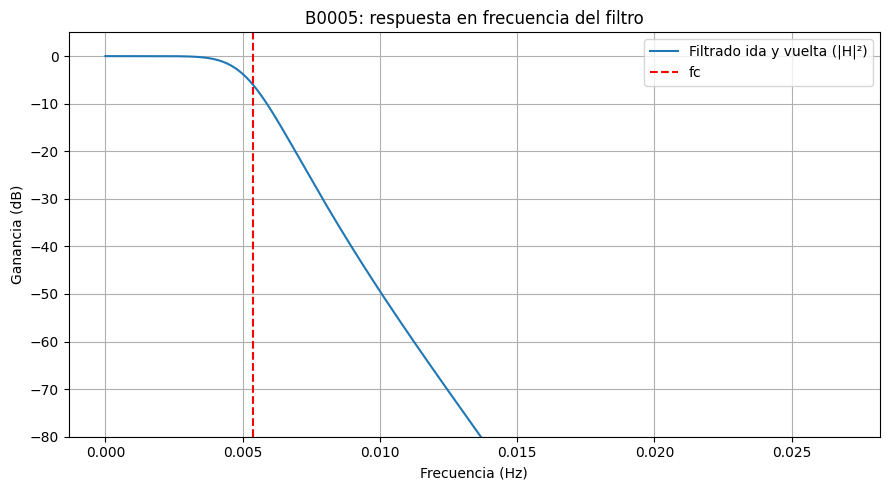

In [10]:
fc = FC_FRAC * nyq
assert 0 < fc < nyq, "fc debe estar entre 0 y fs/2"
sos = butter(ORDEN, fc, btype="low", fs=fs, output="sos")
assert len(tension_u) > 6 * len(sos) + 3, "Señal demasiado corta para sosfiltfilt con este orden"
tension_f = sosfiltfilt(sos, tension_u)

print(f"Butterworth orden {ORDEN} · fc = {fc:.5f} Hz (periodo {1 / fc:.0f} s) · fs = {fs:.5f} Hz · fc/(fs/2) = {FC_FRAC}")

w, h = sosfreqz(sos, worN=2048, fs=fs)
plt.figure(figsize=(9, 5))
plt.plot(w, 20 * np.log10(np.abs(h) ** 2 + 1e-12), label="Filtrado ida y vuelta (|H|²)")
plt.axvline(fc, color="r", ls="--", label="fc")
plt.title("B0005: respuesta en frecuencia del filtro")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Ganancia (dB)")
plt.ylim(-80, 5)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 8. Gráfica H: tensión original y filtrada

Dibujamos ambas señales con los mismos ejes y, debajo, ampliaciones del inicio, del tramo central y del final para no exagerar ni ocultar diferencias.

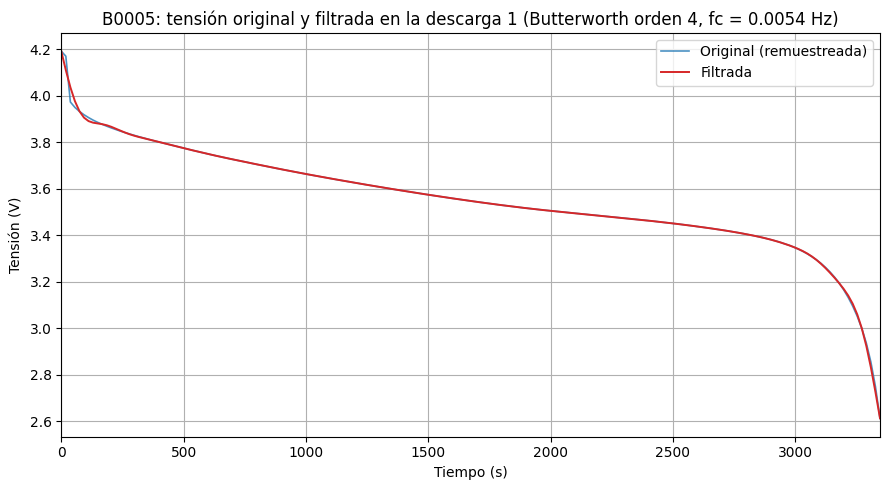

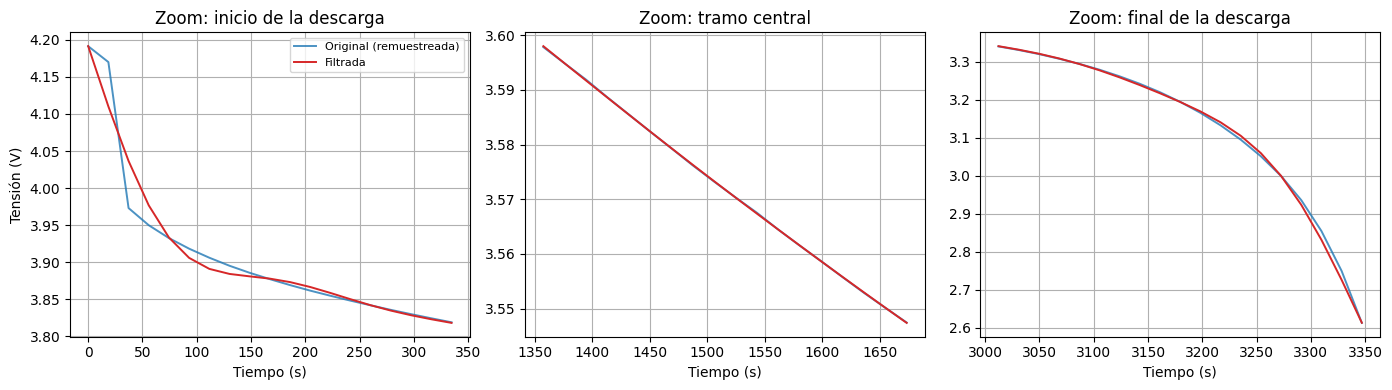

In [11]:
plt.figure(figsize=(9, 5))
plt.plot(tiempo_u, tension_u, color="tab:blue", lw=1.2, alpha=0.8, label="Original (remuestreada)")
plt.plot(tiempo_u, tension_f, color="tab:red", lw=1.4, label="Filtrada")
plt.title(f"B0005: tensión original y filtrada en la descarga {N_DESCARGA} (Butterworth orden {ORDEN}, fc = {fc:.4f} Hz)")
plt.xlabel("Tiempo (s)")
plt.ylabel("Tensión (V)")
plt.xlim(tiempo_u[0], tiempo_u[-1])
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(carpeta_graficas / f"B0005_descarga{N_DESCARGA}_H_tension_original_filtrada.png", dpi=150)
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, m, titulo in [(ax[0], m_inicio, "Zoom: inicio de la descarga"),
                     (ax[1], m_centro, "Zoom: tramo central"),
                     (ax[2], m_final, "Zoom: final de la descarga")]:
    a.plot(tiempo_u[m], tension_u[m], color="tab:blue", lw=1.4, alpha=0.8, label="Original (remuestreada)")
    a.plot(tiempo_u[m], tension_f[m], color="tab:red", lw=1.4, label="Filtrada")
    a.set_title(titulo)
    a.set_xlabel("Tiempo (s)")
    a.grid(True)
ax[0].set_ylabel("Tensión (V)")
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(carpeta_graficas / f"B0005_descarga{N_DESCARGA}_H_zoom.png", dpi=150)
plt.show()

### Interpretación de la Gráfica H 

Las curvas original y filtrada coinciden en casi todo el recorrido. En el tramo central son indistinguibles: la señal es una recta y el filtro no tiene nada que suavizar. Las diferencias aparecen en los dos extremos: el filtro redondea el codo inicial, donde la tensión cae muy deprisa, y en la rodilla final la curva filtrada queda por debajo de la original desde unos 3290 s, hasta unos 23 mV. Las dos coinciden en la última muestra, pero eso se debe a que se queda ahí desde del extremo por la extensión impar del filtrado (padtype="odd") y no a una buena reproducción, como se comprueba en la sección 10.

**Comparación de dos cortes (Gráfica H2).** Repetimos el filtrado con un corte alto (0,8·f<sub>s</sub>/2) para ver cómo cambia el efecto en el inicio y el final.

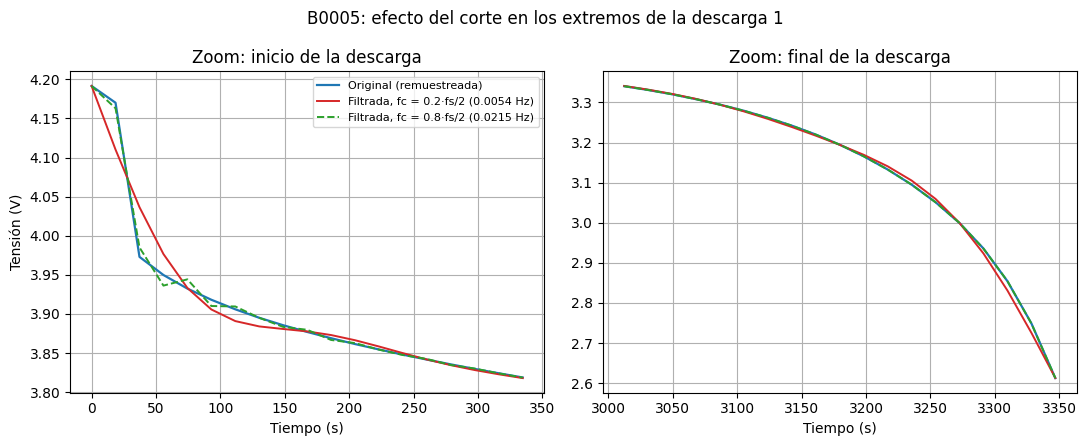

fc/Nyquist = 0.2: RMS = 7.60 mV · máx = 63.56 mV · V final filtrada − original = +0.33 mV
fc/Nyquist = 0.8: RMS = 1.85 mV · máx = 13.57 mV · V final filtrada − original = +0.06 mV


In [12]:
fc2 = FC_FRAC_COMP * nyq
sos2 = butter(ORDEN, fc2, btype="low", fs=fs, output="sos")
tension_f2 = sosfiltfilt(sos2, tension_u)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, m, titulo in [(ax[0], m_inicio, "Zoom: inicio de la descarga"), (ax[1], m_final, "Zoom: final de la descarga")]:
    a.plot(tiempo_u[m], tension_u[m], color="tab:blue", lw=1.6, label="Original (remuestreada)")
    a.plot(tiempo_u[m], tension_f[m], color="tab:red", lw=1.4, label=f"Filtrada, fc = {FC_FRAC}·fs/2 ({fc:.4f} Hz)")
    a.plot(tiempo_u[m], tension_f2[m], color="tab:green", lw=1.4, ls="--", label=f"Filtrada, fc = {FC_FRAC_COMP}·fs/2 ({fc2:.4f} Hz)")
    a.set_title(titulo)
    a.set_xlabel("Tiempo (s)")
    a.grid(True)
ax[0].set_ylabel("Tensión (V)")
ax[0].legend(fontsize=8)
fig.suptitle(f"B0005: efecto del corte en los extremos de la descarga {N_DESCARGA}")
plt.tight_layout()
plt.savefig(carpeta_graficas / f"B0005_descarga{N_DESCARGA}_H2_comparacion_cortes.png", dpi=150)
plt.show()

for nombre, y in [(FC_FRAC, tension_f), (FC_FRAC_COMP, tension_f2)]:
    e = tension_u - y
    print(f"fc/Nyquist = {nombre}: RMS = {1e3 * np.sqrt(np.mean(e ** 2)):.2f} mV · máx = {1e3 * np.abs(e).max():.2f} mV · "
          f"V final filtrada − original = {1e3 * (y[-1] - tension_u[-1]):+.2f} mV")

### Interpretación de la Gráfica H2

Con 0,2·f<sub>s</sub>/2 el RMS de la diferencia es de 7,60 mV y el máximo de 63,56 mV; con 0,8·f<sub>s</sub>/2 baja a 1,85 mV y 13,57 mV. El corte alto sigue mejor la caída inicial y la rodilla, pero es también el que menos suaviza (sección 6). La diferencia en el valor final es de +0,33 mV y +0,06 mV respectivamente.

## 9. Medidas antes y después del filtrado

Calculamos las mismas medidas en la señal original (remuestreada) y en la filtrada: tensión inicial y final, ΔV = V<sub>inicial</sub> − V<sub>final</sub>, extremos, ruido estimado, pendiente máxima y tiempo hasta un nivel de tensión (V_CRITERIO). Este nivel es un umbral de referencia que fijamos al comienzo de la rodilla final, no es el criterio de fin de descarga del ensayo. Una diferencia fuerte en V inicial, V final o ΔV indicaría sobrefiltrado o problemas en los bordes.

In [13]:
def tiempo_hasta(tt, yy, umbral):
    if umbral is None:
        return np.nan
    idx = np.where(yy <= umbral)[0]
    if len(idx) == 0 or idx[0] == 0:
        return np.nan
    i = idx[0]
    return float(np.interp(umbral, [yy[i], yy[i - 1]], [tt[i], tt[i - 1]]))

def medidas(yy):
    out = {
        "V inicial (V)": yy[0],
        "V final (V)": yy[-1],
        "ΔV = V_ini − V_fin (V)": yy[0] - yy[-1],
        "V mínima (V)": yy.min(),
        "V máxima (V)": yy.max(),
        "σ ruido estimada (mV)": 1e3 * sigma_ruido(yy),
        "σ ruido robusta (mV)": 1e3 * sigma_robusta(yy),
        "Pendiente máx. |dV/dt| (mV/s)": 1e3 * np.abs(np.gradient(yy, tiempo_u)).max(),
    }
    if V_CRITERIO is not None:
        out[f"Tiempo hasta V ≤ {V_CRITERIO} V (s)"] = tiempo_hasta(tiempo_u, yy, V_CRITERIO)
    return out

med_orig, med_filt = medidas(tension_u), medidas(tension_f)
tabla = pd.DataFrame({"Original": med_orig, "Filtrada": med_filt})
tabla["Diferencia (filt − orig)"] = tabla["Filtrada"] - tabla["Original"]
tabla["Dif. relativa (%)"] = 100 * tabla["Diferencia (filt − orig)"] / tabla["Original"].abs()
display(tabla.round(4))

r = tension_u - tension_f
print(f"RMS(orig − filt) = {1e3 * np.sqrt(np.mean(r ** 2)):.3f} mV · máx|orig − filt| = {1e3 * np.abs(r).max():.3f} mV")
print(f"Reducción de la σ de ruido estimada: {med_orig['σ ruido estimada (mV)']:.3f} → {med_filt['σ ruido estimada (mV)']:.3f} mV "
      f"(factor {med_orig['σ ruido estimada (mV)'] / max(med_filt['σ ruido estimada (mV)'], 1e-12):.1f})")

,Original,Filtrada,Diferencia (filt − orig),Dif. relativa (%)
V inicial (V),4.1915,4.1916,0.0001,0.0014
V final (V),2.6125,2.6128,0.0003,0.0125
ΔV = V_ini − V_fin (V),1.5790,1.5788,-0.0003,-0.0168
V mínima (V),2.6125,2.6128,0.0003,0.0125
V máxima (V),4.1915,4.1916,0.0001,0.0014
σ ruido estimada (mV),7.6768,1.4202,-6.2566,-81.5001
σ ruido robusta (mV),0.1086,0.0212,-0.0874,-80.4408
Pendiente máx. |dV/dt| (mV/s),7.3484,6.0642,-1.2841,-17.4750
Tiempo hasta V ≤ 3.2 V (s),3175.6652,3175.0215,-0.6437,-0.0203


RMS(orig − filt) = 7.605 mV · máx|orig − filt| = 63.556 mV
Reducción de la σ de ruido estimada: 7.677 → 1.420 mV (factor 5.4)


### Interpretación de la tabla antes y después (descarga 1)

Las medidas básicas casi no cambian: V inicial pasa de 4,1915 V a 4,1916 V, V final de 2,6125 V a 2,6128 V y ΔV de 1,5790 V a 1,5788 V (−0,27 mV). El tiempo hasta 3,2 V varía 0,64 s (−0,02 %). La σ de ruido estimada baja de 7,68 mV a 1,42 mV (factor 5,4), pero, como se vio en la sección 5, esa σ está inflada por la curvatura real, así que la reducción es sobre todo **suavizado de la caída inicial y de la rodilla** y no eliminación de ruido. Lo confirma la pendiente máxima, que disminuye de 7,348 mV/s a 6,064 mV/s (−17,5 %): el filtro recorta un rasgo real de la señal.

## 10. Riesgos: extremos y final de la descarga

**(a) Efecto de borde.** El filtrado ida y vuelta extiende la señal en los extremos y ahí es donde más se aleja de la original. Comparamos el error en los extremos con el del centro.

**(b) Caída final.** Al final de una descarga la tensión cae de forma brusca. Para un paso bajo esa caída es una variación rápida *real*: la suaviza y puede arrastrar el valor final. Comprobamos si hay un aumento de tensión por recuperación entre las últimas muestras y cuánto cambia el valor filtrado de un punto si se recorta el final de la señal.

In [14]:
n_ext = max(3, int(0.02 * len(tension_u)))
rms_mV = lambda z: 1e3 * np.sqrt(np.mean(z ** 2))
print(f"Error RMS orig−filt (mV): inicio ({n_ext} muestras) = {rms_mV(r[:n_ext]):.3f} · centro = {rms_mV(r[n_ext:-n_ext]):.3f} · final ({n_ext} muestras) = {rms_mV(r[-n_ext:]):.3f}")
print(f"Error en la última muestra: V_fin filtrada − original = {1e3 * (tension_f[-1] - tension_u[-1]):.2f} mV · primera muestra: {1e3 * (tension_f[0] - tension_u[0]):.2f} mV")
print(f"Cociente error extremos/centro: inicio = {rms_mV(r[:n_ext]) / rms_mV(r[n_ext:-n_ext]):.1f} · final = {rms_mV(r[-n_ext:]) / rms_mV(r[n_ext:-n_ext]):.1f}")

k = min(8, len(tension) - 1)
print("\nÚltimos cambios de tensión en los datos originales (V):", np.round(np.diff(tension)[-k:], 4))
print("Último Δt (s):", np.round(np.diff(tiempo)[-k:], 2))
sube = np.diff(tension)[-k:] > 3 * max(sigma0, 1e-9)
print("Aaumento de tensión: 3σ entre las últimas muestras (posible recuperación)?", bool(sube.any()))
print("Diferencia filtrada − original en las últimas 5 muestras (mV):", np.round(1e3 * (tension_f[-5:] - tension_u[-5:]), 2))

filas = []
for kk in [0, 2, 5, 10]:
    if len(tension_u) - kk <= 6 * len(sos) + 3:
        continue
    yk = sosfiltfilt(sos, tension_u[:len(tension_u) - kk])
    j = len(tension_u) - kk - 1
    filas.append({"muestras recortadas al final": kk, "t del último punto (s)": tiempo_u[j],
                  "V original (V)": tension_u[j], "V filtrada, registro completo (V)": tension_f[j],
                  "V filtrada, registro recortado (V)": yk[-1], "diferencia (mV)": 1e3 * (yk[-1] - tension_f[j])})
display(pd.DataFrame(filas).round(4))

Error RMS orig−filt (mV): inicio (3 muestras) = 50.427 · centro = 3.158 · final (3 muestras) = 19.090
Error en la última muestra: V_fin filtrada − original = 0.33 mV · primera muestra: 0.06 mV
Cociente error extremos/centro: inicio = 16.0 · final = 6.0

Últimos cambios de tensión en los datos originales (V): [-0.0327 -0.0379 -0.0439 -0.0523 -0.0639 -0.0832 -0.1088 -0.1448]
Último Δt (s): [19.56 19.72 19.61 19.7  19.64 19.66 19.61 19.7 ]
Aaumento de tensión: 3σ entre las últimas muestras (posible recuperación)? False
Diferencia filtrada − original en las últimas 5 muestras (mV): [  0.25 -12.33 -23.21 -23.55   0.33]


,muestras recortadas al final,t del último punto (s),V original (V),"V filtrada, registro completo (V)","V filtrada, registro recortado (V)",diferencia (mV)
0,0,3346.9370,2.6125,2.6128,2.6128,0.0000
1,2,3309.7488,2.8542,2.8310,2.8545,23.4507
2,5,3253.9665,3.0512,3.0594,3.0514,-8.0756
3,10,3160.9961,3.2200,3.2172,3.2201,2.8221


### Interpretación de los riesgos 

El error RMS en los extremos es mucho mayor que en el centro: 50,43 mV al inicio y 19,09 mV al final frente a 3,16 mV en el centro (cocientes de 16,0 y 6,0). Entre las últimas muestras no hay ningún aumento de tensión, solo una caída cada vez más rápida (de −0,03 V a −0,14 V por muestra), y por eso la fase activa no incluye la recuperación. En las últimas cinco muestras la filtrada se separa de la original hasta unos 23 mV salvo en la última, que queda anclada (+0,33 mV). Además, el valor filtrado de un punto depende de lo que viene después: al recortar dos muestras del final, el valor filtrado en ese punto cambia 23,45 mV.

Con este corte, V final y el tiempo hasta un umbral deben leerse de la señal original, el filtrado solo se usa para la componente lenta.

## 11. Mismo procedimiento en las descargas 1, 80 y 160

Aplicamos el mismo orden y el mismo cociente f<sub>c</sub>/(f<sub>s</sub>/2) a las tres descargas que compara Andrea, para que las tablas del grupo cuadren. Como el muestreo puede ser distinto en cada descarga, mostramos también el Δt mínimo y máximo. Si una descarga no existe en el CSV, se omite.

In [15]:
def procesar(n):
    dd = descargas[descargas["numero_tipo"] == n][["tiempo_s", "tension_V", "corriente_A"]].dropna().sort_values("tiempo_s")
    dd = dd.groupby("tiempo_s", as_index=False).mean()
    if len(dd) < 20:
        return None
    tt = dd["tiempo_s"].to_numpy() - dd["tiempo_s"].iloc[0]
    vv = dd["tension_V"].to_numpy()
    ii = dd["corriente_A"].to_numpy()
    if SOLO_FASE_ACTIVA and (np.abs(ii) >= UMBRAL_I).any():
        kf = int(np.where(np.abs(ii) >= UMBRAL_I)[0].max())
        tt, vv = tt[:kf + 1], vv[:kf + 1]
    paso = np.diff(tt)
    d0 = np.median(paso)
    nn = int(round(tt[-1] / d0)) + 1
    tg = np.linspace(0, tt[-1], nn)
    vg = np.interp(tg, tt, vv)
    fs_n = 1 / (tg[1] - tg[0])
    sos_n = butter(ORDEN, FC_FRAC * fs_n / 2, btype="low", fs=fs_n, output="sos")
    yy = sosfiltfilt(sos_n, vg)
    return {"descarga": n, "muestras": len(tt), "duración (s)": tt[-1],
            "Δt mín (s)": paso.min(), "Δt mediana (s)": d0, "Δt máx (s)": paso.max(),
            "fs (Hz)": fs_n, "fc (Hz)": FC_FRAC * fs_n / 2,
            "σ ruido orig (mV)": 1e3 * sigma_ruido(vg), "σ ruido filt (mV)": 1e3 * sigma_ruido(yy),
            "V ini orig (V)": vg[0], "V fin orig (V)": vg[-1], "ΔV orig (V)": vg[0] - vg[-1],
            "V ini filt (V)": yy[0], "V fin filt (V)": yy[-1], "ΔV filt (V)": yy[0] - yy[-1],
            "RMS(orig−filt) (mV)": 1e3 * np.sqrt(np.mean((vg - yy) ** 2))}

res3 = [procesar(n) for n in (1, 80, 160)]
res3 = pd.DataFrame([x for x in res3 if x is not None])
display(res3.round(4))

,descarga,muestras,duración (s),Δt mín (s),Δt mediana (s),Δt máx (s),fs (Hz),fc (Hz),σ ruido orig (mV),σ ruido filt (mV),V ini orig (V),V fin orig (V),ΔV orig (V),V ini filt (V),V fin filt (V),ΔV filt (V),RMS(orig−filt) (mV)
0,1,180,3346.937,16.781,18.579,19.719,0.0538,0.0054,7.6768,1.4202,4.1915,2.6125,1.5790,4.1916,2.6128,1.5788,7.6047
1,80,301,2813.594,9.297,9.375,10.156,0.1066,0.0107,5.7566,0.7095,4.1985,2.6888,1.5097,4.1986,2.6891,1.5095,5.5188
2,160,251,2345.813,9.297,9.375,10.156,0.1066,0.0107,6.8799,0.8685,4.1954,2.6663,1.5291,4.1955,2.6664,1.5290,6.5827


### Interpretación de las tres descargas

En las tres descargas el filtro conserva las medidas básicas: la diferencia en ΔV es de 0,2 a 0,3 mV (1,5790 → 1,5788 V en la descarga 1, 1,5097 → 1,5095 V en la 80 y 1,5291 → 1,5290 V en la 160) y el RMS de la diferencia está entre 5,5 y 7,6 mV. La σ estimada se reduce de 7,68 a 1,42 mV, de 5,76 a 0,71 mV y de 6,88 a 0,87 mV, con la misma salvedad de que parte de esa σ es curvatura real.

Dos precisiones. Primero, las descargas 80 y 160 tienen un Δt mediano de 9,375 s frente a 18,579 s de la descarga 1, así que, con el mismo cociente f<sub>c</sub>/(f<sub>s</sub>/2), el corte en Hz es distinto (0,0107 Hz frente a 0,0054 Hz) y por tanto también el periodo mínimo que se deja pasar. Segundo, la duración de la fase activa baja de 3346,9 s a 2813,6 s y a 2345,8 s.

## 12. Guardar tablas y parámetros

Guardamos en resultados/ el barrido de cortes, la tabla antes y después, la tabla de las tres descargas y un archivo .json con los parámetros del filtro (incluido el tratamiento del muestreo), para poder reproducir el análisis. Las figuras ya se han guardado en graficas/.

In [16]:
parametros = {
    "bateria": "B0005", "descarga": int(N_DESCARGA), "senal": "tension_V",
    "fase": "activa (|I| >= %.1f A)" % UMBRAL_I if SOLO_FASE_ACTIVA else "registro completo",
    "n_muestras_originales": int(len(tiempo)), "duracion_s": float(tiempo[-1]),
    "dt_min_s": float(dt.min()), "dt_mediana_s": float(dt_med), "dt_max_s": float(dt.max()),
    "muestreo_uniforme": MUESTREO_UNIFORME,
    "remuestreo": "interpolación lineal (np.interp) en rejilla uniforme con extremos incluidos (linspace)",
    "n_muestras_remuestreadas": int(n_u), "dt_uniforme_s": float(dt_u),
    "fs_Hz": float(fs), "nyquist_Hz": float(nyq),
    "filtro": "Butterworth paso bajo (scipy.signal.butter, salida sos)", "orden": int(ORDEN),
    "fc_Hz": float(fc), "fc_sobre_nyquist": float(FC_FRAC), "periodo_de_corte_s": float(1 / fc),
    "aplicacion": "sosfiltfilt (fase cero, ida y vuelta; padtype='odd' por defecto)",
}

barrido.round(6).to_csv(carpeta_resultados / f"barrido_cortes_d{N_DESCARGA}.csv", index=False, encoding="utf-8-sig")
tabla.round(6).to_csv(carpeta_resultados / f"tabla_antes_despues_d{N_DESCARGA}.csv", index_label="medida", encoding="utf-8-sig")
res3.round(6).to_csv(carpeta_resultados / "tabla_filtrado_descargas_1_80_160.csv", index=False, encoding="utf-8-sig")
with open(carpeta_resultados / f"parametros_filtrado_d{N_DESCARGA}.json", "w", encoding="utf-8") as f:
    json.dump(parametros, f, ensure_ascii=False, indent=2)

for clave, valor in parametros.items():
    print(f"{clave:28s} {valor}")
print("\nTablas y parámetros guardados en:", carpeta_resultados)
print("Figuras guardadas en:", carpeta_graficas)

bateria                      B0005
descarga                     1
senal                        tension_V
fase                         activa (|I| >= 0.5 A)
n_muestras_originales        180
duracion_s                   3346.937
dt_min_s                     16.781
dt_mediana_s                 18.57900000000018
dt_max_s                     19.71900000000005
muestreo_uniforme            True
remuestreo                   interpolación lineal (np.interp) en rejilla uniforme con extremos incluidos (linspace)
n_muestras_remuestreadas     181
dt_uniforme_s                18.594094444444444
fs_Hz                        0.05378051633478611
nyquist_Hz                   0.026890258167393054
filtro                       Butterworth paso bajo (scipy.signal.butter, salida sos)
orden                        4
fc_Hz                        0.005378051633478612
fc_sobre_nyquist             0.2
periodo_de_corte_s           185.9409444444444
aplicacion                   sosfiltfilt (fase cero, ida y vuelta; 

## 13. Teoría mínima

Una señal puede tener componentes de **variación lenta** (aquí, la tendencia de la descarga) y de **variación rápida** (el ruido de medida, pero también la caída inicial y la rodilla final). Un **filtro paso bajo** deja pasar las primeras y atenúa las segundas, por lo que suaviza las fluctuaciones de medida. La **frecuencia de muestreo** fija la frecuencia máxima representable (f<sub>s</sub>/2) y la **frecuencia de corte** decide qué se considera rápido. Si el corte es demasiado bajo se eliminan cambios reales y se distorsionan los extremos; si es demasiado alto, el ruido no se atenúa. El Butterworth se elige por tener una respuesta plana en la banda de paso, y sosfiltfilt evita el retardo de fase a costa de efectos en los bordes.

## 14. Conclusiones

Se ha filtrado la tensión de la fase activa de la descarga 1 de la batería B0005 (180 muestras, 3346,9 s) con un Butterworth paso bajo de orden 4 y corte de **0,0054 Hz** (0,2·f<sub>s</sub>/2, con f<sub>s</sub> = 0,05378 Hz), aplicado con sosfiltfilt. El muestreo es prácticamente uniforme (Δt entre 16,8 y 19,7 s, sin huecos) y se ha remuestreado a una rejilla exacta incluyendo el último instante.

**La señal apenas contiene ruido.** La σ robusta es de 0,109 mV (0,007 % de ΔV = 1,579 V), el tramo central es una recta sin dispersión visible y el espectro es plano por encima de unos 0,005 Hz. La reducción de la σ estimada de 7,68 mV a 1,42 mV corresponde a suavizar rasgos reales, no a eliminar ruido.

**Qué conserva y qué distorsiona el filtro.** Conserva V inicial, V final y ΔV (diferencias de 0,1 a 0,3 mV), pero redondea el codo inicial, queda hasta unos 23 mV por debajo de la original en la rodilla final y reduce la pendiente máxima un 17,5 %. Ningún corte del barrido quita ruido sin alterar los extremos. Por eso V final y el tiempo hasta un umbral deben leerse de la señal original, y el filtrado queda como una ilustración de la compensación entre suavizado y distorsión. Los resultados son análogos en las descargas 80 y 160.

**Limitaciones:** se estudia una sola señal (tensión) de una sola batería; la σ por segunda diferencia es solo orientativa; el nivel V_CRITERIO es un umbral de referencia y no un criterio de fin de descarga; con el mismo cociente f<sub>c</sub>/(f<sub>s</sub>/2) el corte en Hz cambia entre descargas con distinto muestreo; y para hablar de degradación hay que comparar capacidad y condiciones de ensayo.